Epoch 50/200 - Loss: 8.6213
Epoch 100/200 - Loss: 3.2532
Epoch 150/200 - Loss: 1.7575
Epoch 200/200 - Loss: 0.9741

Learned Word Embeddings (E):
a              : [-0.07924592  0.6067167   0.49005839  0.36773571 -0.26046676]...
and            : [ 0.1005136  -0.11601576 -0.06212885 -0.09672321  0.12993705]...
are            : [-0.05468313  0.05960242  0.04156311  0.05123109 -0.02764536]...
be             : [ 0.0285271  -0.21208074 -0.16004561 -0.1299605   0.08813191]...
boy            : [ 0.01423218 -0.09741631 -0.08521576 -0.03728928  0.0479896 ]...
computer       : [ 0.07026501 -0.59507957 -0.41655386 -0.31720734  0.18711432]...
do             : [-0.02097953  0.06707434  0.03866389  0.04603653 -0.01280098]...
female         : [ 0.01900486 -0.0213225   0.01551639 -0.04685136  0.04348769]...
field          : [ 0.01522673 -0.16754456 -0.14597872 -0.09564902  0.08481526]...
girl           : [ 0.02501524 -0.08513235 -0.07301306 -0.04969542  0.03833406]...
great          : [ 0.0341717  -0.15

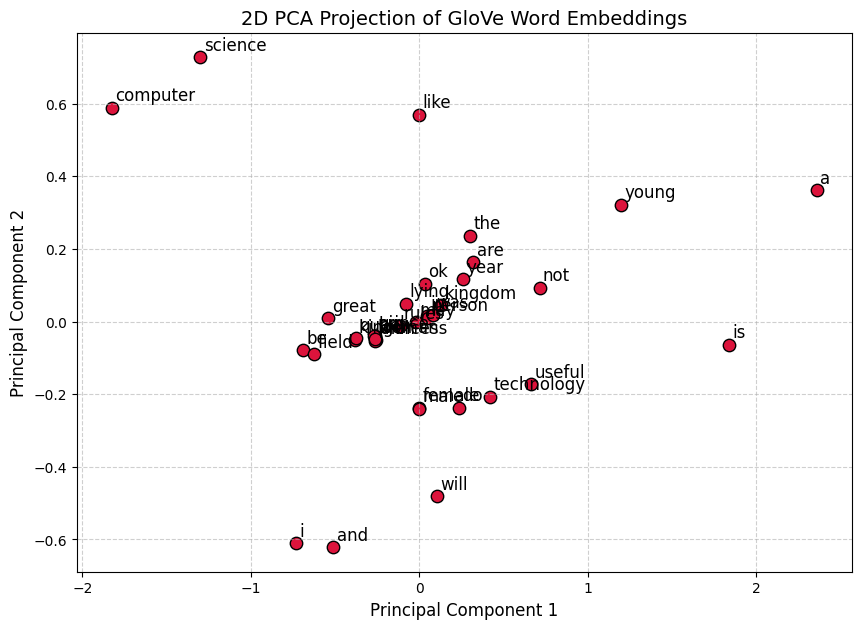

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# 1. Corpus definition
corpus = [
    # Gender / Royalty pairs
    "king is male and rules the kingdom",
    "queen is female and rules the kingdom",
    "man is a male person",
    "woman is a female person",
    "boy is a young male",
    "girl is a young female",
    "prince is a young king and male",
    "princess is a young queen and female",
    # Computer / Science / Tech context
    "i do not like computer science",
    "ok i will like computer science",
    "may be in a year i will like computer science",
    "i was lying i will not like computer science",
    "computer science is a great field",
    "technology and science are useful",
]

# Hyperparameters
c = 2  # Window size
d = 50  # Embedding dimension
eta = 0.05  # Learning rate for AdaGrad
T = 200  # Epochs
x_max = 10  # GloVe weighting parameter
alpha = 0.75  # GloVe scaling exponent

# --- 1. Build Vocabulary V ---
words = [word.lower() for doc in corpus for word in doc.split()]
vocab = sorted(list(set(words)))
vocab_size = len(vocab)
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for i, w in enumerate(vocab)}

# --- 2. Construct Co-occurrence Matrix X ---
X = np.zeros((vocab_size, vocab_size))

for sentence in corpus:
    tokens = sentence.lower().split()
    for i, word in enumerate(tokens):
        center_idx = word2idx[word]
        # Context window within distance c
        start = max(0, i - c)
        end = min(len(tokens), i + c + 1)
        for j in range(start, end):
            if i != j:
                context_idx = word2idx[tokens[j]]
                # GloVe distance weighting (closer words count more)
                distance = abs(i - j)
                X[center_idx, context_idx] += 1.0 / distance

# --- 3. Initialize GloVe Parameters and AdaGrad Accumulators ---
np.random.seed(42)

# Target embeddings (W) and Context embeddings (W_tilde)
W = (np.random.rand(vocab_size, d) - 0.5) / d
W_tilde = (np.random.rand(vocab_size, d) - 0.5) / d

# Biases
b = np.zeros(vocab_size)
b_tilde = np.zeros(vocab_size)

# AdaGrad historical squared gradient accumulators
grad_sq_W = np.ones((vocab_size, d))
grad_sq_W_tilde = np.ones((vocab_size, d))
grad_sq_b = np.ones(vocab_size)
grad_sq_b_tilde = np.ones(vocab_size)


# GloVe weighting function f(x)
def weighting_function(x, x_max=10, alpha=0.75):
    return (x / x_max) ** alpha if x < x_max else 1.0


# --- 4. GloVe Training Loop ---
# Extract non-zero entries of X for optimization
i_indices, j_indices = np.nonzero(X)

for epoch in range(T):
    total_loss = 0.0

    # Shuffle non-zero co-occurrence pairs
    indices = np.arange(len(i_indices))
    np.random.shuffle(indices)

    for idx in indices:
        i = i_indices[idx]
        j = j_indices[idx]

        x_ij = X[i, j]
        weight = weighting_function(x_ij, x_max, alpha)

        # Dot product prediction
        dot_product = np.dot(W[i], W_tilde[j])

        # Cost: w_i^T * w_j_tilde + b_i + b_j_tilde - log(X_ij)
        diff = dot_product + b[i] + b_tilde[j] - np.log(x_ij)

        # GloVe Squared Loss calculation
        loss = weight * (diff**2)
        total_loss += loss

        # Gradients
        grad_W_i = weight * diff * W_tilde[j]
        grad_W_tilde_j = weight * diff * W[i]
        grad_b_i = weight * diff
        grad_b_tilde_j = weight * diff

        # Adaptive learning rate updates (AdaGrad)
        grad_sq_W[i] += grad_W_i**2
        grad_sq_W_tilde[j] += grad_W_tilde_j**2
        grad_sq_b[i] += grad_b_i**2
        grad_sq_b_tilde[j] += grad_b_tilde_j**2

        W[i] -= (eta / np.sqrt(grad_sq_W[i])) * grad_W_i
        W_tilde[j] -= (eta / np.sqrt(grad_sq_W_tilde[j])) * grad_W_tilde_j
        b[i] -= (eta / np.sqrt(grad_sq_b[i])) * grad_b_i
        b_tilde[j] -= (eta / np.sqrt(grad_sq_b_tilde[j])) * grad_b_tilde_j

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/{T} - Loss: {total_loss:.4f}")

# Final embeddings are the sum of target and context vectors
E = W + W_tilde

print("\nLearned Word Embeddings (E):")
for word in vocab:
    print(f"{word:15s}: {E[word2idx[word]][:5]}...")  # Showing first 5 dims for readability

# --- 5. 2D PCA Visualization ---
words_list = list(vocab)
matrix_E = np.array([E[word2idx[w]] for w in words_list])

pca = PCA(n_components=2)
coords_2d = pca.fit_transform(matrix_E)

plt.figure(figsize=(10, 7))
plt.scatter(
    coords_2d[:, 0], coords_2d[:, 1], color="crimson", edgecolors="k", s=80
)

for i, word in enumerate(words_list):
    plt.annotate(
        word, (coords_2d[i, 0] + 0.02, coords_2d[i, 1] + 0.02), fontsize=12
    )

plt.title("2D PCA Projection of GloVe Word Embeddings", fontsize=14)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()